# MSR-VTT text–video retrieval in the compressed domain: results

This notebook reports the retrieval runs of `main_task_retrieval.py`: learning curves, final metrics, how much each compressed-domain branch (I-frame, residual, motion vector) contributes, and qualitative examples.

It needs **no GPU, no model and no video decoding**. It reads two things from each run's `--output_dir`:

- the MLflow history (learning curves);
- `embeddings_val.npz` / `embeddings_test.npz`: the selected model's caption embeddings and one video embedding per branch. `embeddings_val.npz` is written during training whenever a new best model is saved; `embeddings_test.npz` by `--do_eval`.

All plotting and metric code lives in `reports/analysis.py`; the cells below only call it.

## Configuration

In [1]:
# name shown in the figures -> the run's --output_dir. The first entry is the reference run.
RUNS = {
    # "full": "/tmp/ckpts/ckpt_msrvtt_compressed_v2",
    "full": "/storage/ckpts/msrvtt_small_arch",
    # "zero-shot I-frame": "/storage/ckpts/zeroshot_iframe",
    # "I-frame only":      "/storage/ckpts/msrvtt_iframe",
    # "residual + MV":     "/storage/ckpts/msrvtt_residual_mv",
}

REPORT_RUN = "full"        # the run analysed in detail (branch ablation, examples)
SPLIT = "val"              # "val" while comparing variants; "test" for the final numbers

# Only for runs tracked with --mlflow_tracking_uri whose output_dir has no mlflow_run.json:
# name -> {"tracking_uri": "...", "run_id": "..."}
MLFLOW_OVERRIDES = {}

# Optional: the re-encoded videos, to show I-frame thumbnails of retrieved videos (needs coviar).
FEATURES_PATH = "/storage/data/msrvtt/mpeg4_videos"

N_EXAMPLES = 3             # successes and failures shown per direction
TOP_K = 5
SEED = 0

In [2]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "reports" else Path.cwd()   # compressed_domain/
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "reports"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import analysis as an

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 2)

runs = [an.load_run(path, name=name, **MLFLOW_OVERRIDES.get(name, {})) for name, path in RUNS.items()]
by_name = {run["name"]: run for run in runs}
report = by_name[REPORT_RUN]

summary = pd.DataFrame([{
    "run": run["name"], "output_dir": run["output_dir"],
    "mlflow history": "yes" if run["run_id"] else "no",
    "embeddings": ", ".join(sorted(run["embeddings"])) or "none",
} for run in runs]).set_index("run")
display(summary)

def need(run, split):
    """The run's embeddings for `split`, or None after saying how to produce them."""
    emb = run["embeddings"].get(split)
    if emb is None:
        display(Markdown(
            f"**No `embeddings_{split}.npz` in `{run['output_dir']}`.** Create it by running the run's training "
            f"command with `--do_eval --eval_on {split}` in place of `--do_train` (same `--output_dir`, "
            f"`--visual_branches` and `--resume_model auto`)."))
    return emb

,output_dir,mlflow history,embeddings
run,,,
full,/storage/ckpts/msrvtt_small_arch,yes,"test, val"


## 1. Setup of each run

The arguments each run was trained with, as recorded by MLflow. Rows that are identical across runs are what the comparison holds fixed; the rows that differ are what is being compared.

In [3]:
KEYS = ["visual_branches", "visual_pooling", "freeze_text", "freeze_layer_num", "mv_init", "modality_loss_weight",
        "lr", "coef_lr", "residual_coef_lr", "mv_coef_lr", "batch_size", "epochs", "max_train_samples",
        "max_frames", "residual_per_gop", "mv_per_gop", "slice_framepos", "max_words", "precision", "seed",
        "train_csv", "val_csv", "test_csv"]
params = pd.DataFrame({run["name"]: an.run_params(run) for run in runs}).reindex(KEYS).dropna(how="all")
display(params.fillna("—") if len(params.columns) and len(params) else Markdown("_No MLflow parameters found._"))

for run in runs:
    for split, emb in run["embeddings"].items():
        print(f"{run['name']:>20s} / {split}: {len(emb['video_ids'])} caption-video pairs, "
              f"branches = {emb['branches']}, failed videos = {len(emb['failed_video_ids'])}")

/tmp/clip4clip/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,full
visual_branches,"['iframe', 'residual', 'mv']"
visual_pooling,modality
freeze_text,1
freeze_layer_num,0
mv_init,random
modality_loss_weight,0.5
lr,0.0001
coef_lr,0.001
residual_coef_lr,0.1
mv_coef_lr,1.0


                full / val: 1000 caption-video pairs, branches = ['iframe', 'residual', 'mv'], failed videos = 0
                full / test: 1000 caption-video pairs, branches = ['iframe', 'residual', 'mv'], failed videos = 0


## 2. Learning curves

The x-axis is the number of optimizer steps since the start of the run; it is continuous across resumed sessions. Validation metrics have one point per epoch.

- **Training loss**: symmetric contrastive loss, averaged over the steps between two log lines.
- **R@K**: share of queries whose correct item is in the top K (higher is better). **Median rank**: lower is better; 1 is perfect and chance is half the number of candidates.

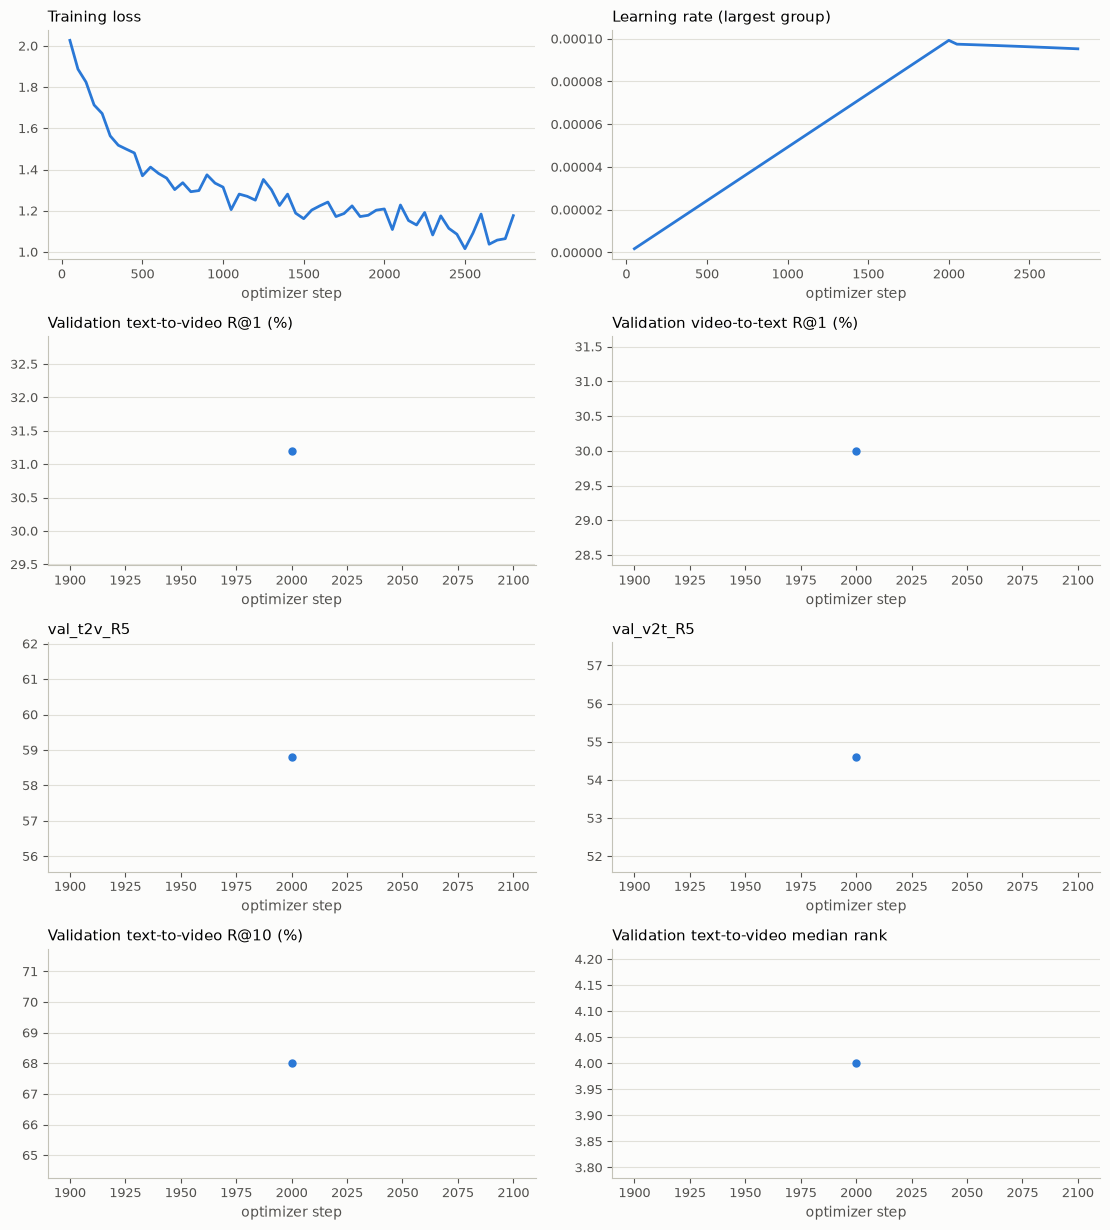

In [4]:
fig, _ = an.plot_learning_curves(runs, ["train_loss", "lr_max", "val_t2v_R1", "val_v2t_R1", "val_t2v_R5", "val_v2t_R5",
                                         "val_t2v_R10", "val_t2v_MedianR"],
    titles={"train_loss": "Training loss", "lr_max": "Learning rate (largest group)",
            "val_t2v_R1": "Validation text-to-video R@1 (%)", "val_v2t_R1": "Validation video-to-text R@1 (%)",
            "val_t2v_R10": "Validation text-to-video R@10 (%)", "val_t2v_MedianR": "Validation text-to-video median rank"})
plt.show()

### What each branch retrieves on its own during training

For the reference run: validation R@1 of the full model, and of each branch's embedding used alone (the other branches left out of the video embedding, nothing retrained). A branch whose line stays near zero is not contributing a text-aligned embedding. These per-branch lines are logged from the code version that added them onward.

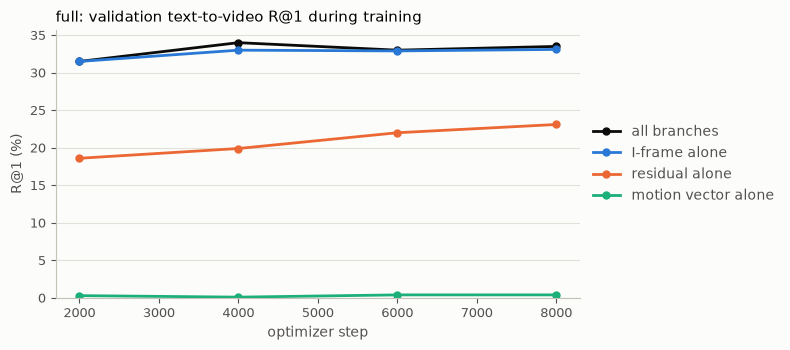

In [5]:
if report["run_id"]:
    an.plot_branch_curves(report)
    plt.show()
else:
    display(Markdown("_No MLflow history for the reference run._"))

### Training diagnostics

Gradient norm per tower (before clipping), the share of Adam second-moment entries that are exactly zero (should be about 0), and peak GPU memory.

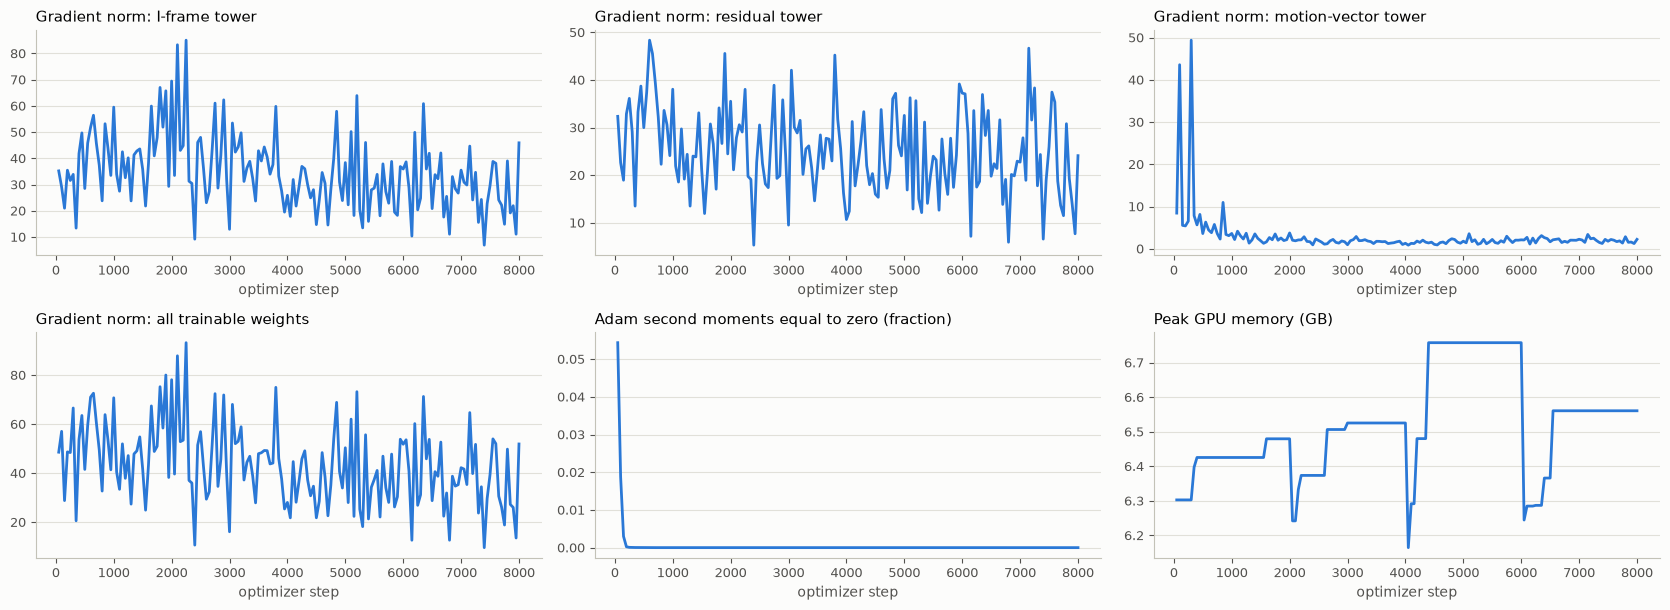

In [6]:
fig, _ = an.plot_learning_curves(runs[:1] if not report["run_id"] else [report],
    ["grad_norm_iframe", "grad_norm_residual", "grad_norm_mv", "grad_norm", "adam_v_zero_frac", "gpu_peak_gb"],
    titles={"grad_norm_iframe": "Gradient norm: I-frame tower", "grad_norm_residual": "Gradient norm: residual tower",
            "grad_norm_mv": "Gradient norm: motion-vector tower", "grad_norm": "Gradient norm: all trainable weights",
            "adam_v_zero_frac": "Adam second moments equal to zero (fraction)", "gpu_peak_gb": "Peak GPU memory (GB)"},
    ncols=3)
plt.show()

## 3. Main results

The selected (best validation R@1) model of every run, using all the branches it was built with. One caption per video; the candidate pool is every video of the split.

**Split: val**

,branches,queries,t2v_R@1,t2v_R@5,t2v_R@10,t2v_MedR,t2v_MeanR,v2t_R@1,v2t_R@5,v2t_R@10,v2t_MedR,v2t_MeanR,failed videos
run,,,,,,,,,,,,,
full,I-frame + residual + motion vector,1000,34.0,58.6,70.3,3.0,32.33,31.7,58.0,69.0,4.0,27.38,0


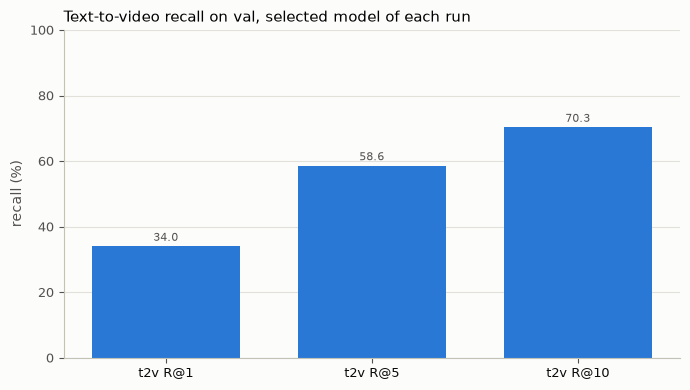

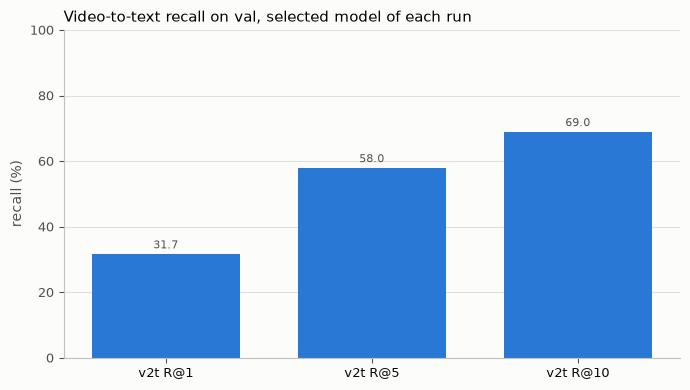

In [7]:
results = an.results_table(runs, SPLIT)
if len(results):
    display(Markdown(f"**Split: {SPLIT}**"))
    display(results)
    an.plot_runs_comparison(results, title=f"Text-to-video recall on {SPLIT}, selected model of each run")
    plt.show()
    an.plot_runs_comparison(results, metrics=("v2t_R@1", "v2t_R@5", "v2t_R@10"),
                            title=f"Video-to-text recall on {SPLIT}, selected model of each run")
    plt.show()
else:
    need(report, SPLIT)

In [8]:
# The other split too, when it has been evaluated (test numbers should be produced once, at the end).
other = "test" if SPLIT == "val" else "val"
other_results = an.results_table(runs, other)
if len(other_results):
    display(Markdown(f"**Split: {other}**"))
    display(other_results)

**Split: test**

,branches,queries,t2v_R@1,t2v_R@5,t2v_R@10,t2v_MedR,t2v_MeanR,v2t_R@1,v2t_R@5,v2t_R@10,v2t_MedR,v2t_MeanR,failed videos
run,,,,,,,,,,,,,
full,I-frame + residual + motion vector,1000,33.9,58.0,68.4,3.0,23.95,31.1,58.1,69.4,4.0,24.52,0


## 4. Contribution of each branch inside the trained model

**Inference-time ablation.** The reference model is evaluated with every subset of its branches: the video embedding is the average of only the chosen branches' embeddings. Nothing is retrained.

How to read it:
- a single branch near chance means that branch's embedding carries no text-relevant information **in this model**;
- if "all branches" is no better than the best single branch, the others add nothing (or add noise) at inference.

This shows what the jointly trained model relies on. It does not show what a branch could do if trained alone; that is the training-time comparison in section 5.

,queries,t2v_R@1,t2v_R@5,t2v_R@10,t2v_MedR,t2v_MeanR,v2t_R@1,v2t_R@5,v2t_R@10,v2t_MedR,v2t_MeanR
branches used,,,,,,,,,,,
I-frame,1000,33.0,56.6,66.4,4.0,39.52,32.8,54.8,67.1,4.0,36.66
residual,1000,19.9,40.4,53.1,9.0,52.51,15.9,36.0,48.1,12.0,54.80
motion vector,1000,0.1,1.4,2.8,258.0,331.97,0.2,0.9,1.7,335.5,377.24
I-frame + residual,1000,32.7,58.9,70.0,3.0,31.84,32.0,58.2,69.5,3.0,27.20
I-frame + motion vector,1000,33.1,55.4,64.8,4.0,41.20,32.7,54.5,67.2,4.0,36.34
residual + motion vector,1000,18.8,40.3,52.3,9.0,54.05,15.8,32.2,44.7,14.0,57.87
I-frame + residual + motion vector,1000,34.0,58.6,70.3,3.0,32.33,31.7,58.0,69.0,4.0,27.38


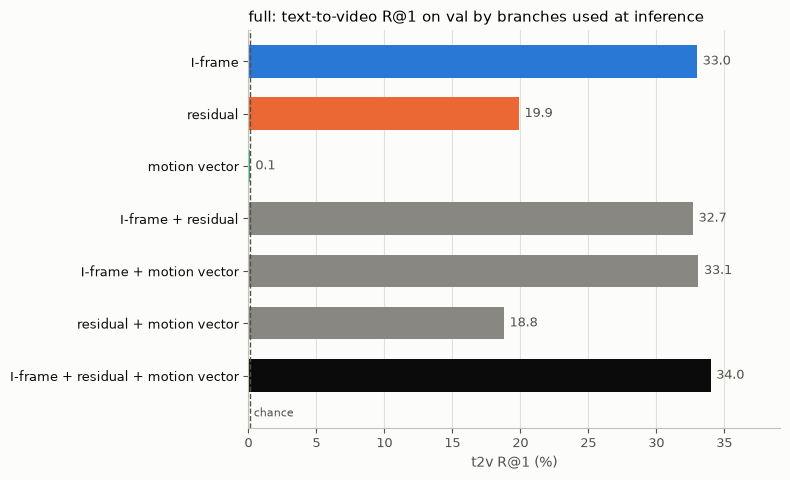

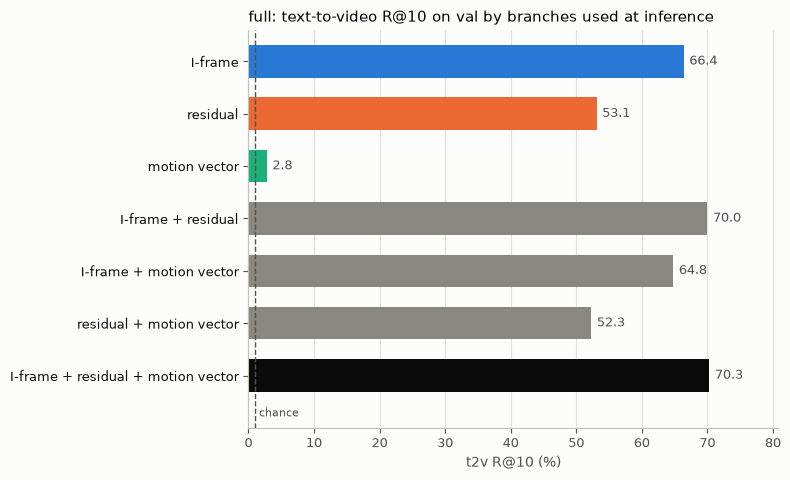

In [9]:
emb = need(report, SPLIT)
if emb is not None and len(emb["branches"]) > 1:
    ablation = an.branch_ablation_table(emb)
    display(ablation.drop(columns=["_subset", "n"]))
    chance = 100.0 / len(emb["video_ids"])
    an.plot_branch_ablation(ablation, "t2v_R@1", chance=chance,
                            title=f"{report['name']}: text-to-video R@1 on {SPLIT} by branches used at inference")
    plt.show()
    an.plot_branch_ablation(ablation, "t2v_R@10", chance=10 * chance,
                            title=f"{report['name']}: text-to-video R@10 on {SPLIT} by branches used at inference")
    plt.show()
elif emb is not None:
    display(Markdown("_The reference model has a single branch (or frame pooling): no subsets to compare._"))

### Recall@K per branch

The same comparison over the whole ranking, not only the top 1, with the chance line for reference.

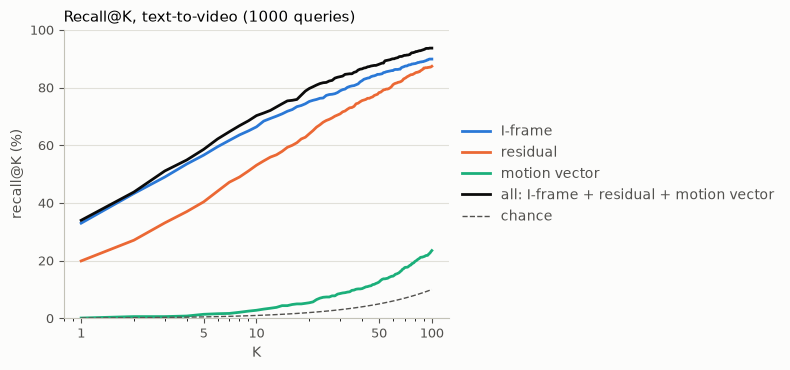

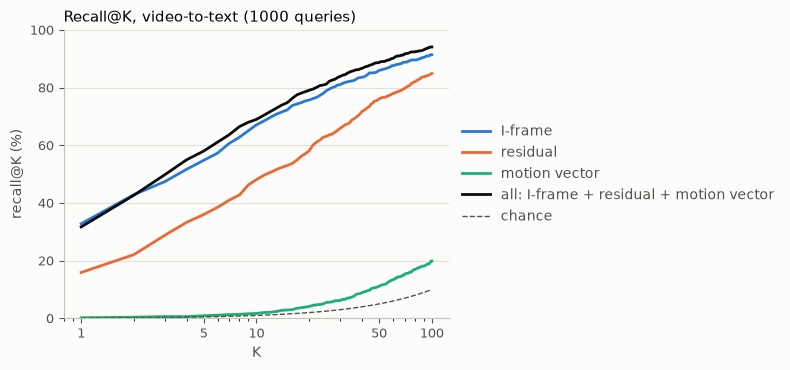

In [10]:
if emb is not None:
    an.plot_recall_curve(emb, direction="t2v")
    plt.show()
    an.plot_recall_curve(emb, direction="v2t")
    plt.show()

### Alignment of each branch with the text

Mean cosine similarity between a caption and its own video's branch embedding (*matched*), against other videos' (*mismatched*). The **gap** is what retrieval can use: a branch with a gap near 0 does not separate the right video from the wrong ones.

In [11]:
if emb is not None:
    display(an.branch_alignment_table(emb).style.format("{:.3f}"))

,matched,mismatched,gap
branch,,,
I-frame,0.282,0.193,0.089
residual,0.195,0.119,0.076
motion vector,-0.075,-0.078,0.003


### Do the other branches help where the I-frame fails?

Starting from the I-frame branch alone, how many queries move into or out of the top 10 when other branches are added. The scatter compares every query's rank with the I-frame alone (x) and with all branches (y): points below the diagonal are queries the full model ranks better.

,in top-10 with I-frame,gained,lost,net
branches used,,,,
I-frame + residual,664,86,50,36
I-frame + motion vector,664,18,34,-16
I-frame + residual + motion vector,664,83,44,39


,in top-1 with I-frame,gained,lost,net
branches used,,,,
I-frame + residual,330,80,83,-3
I-frame + motion vector,330,33,32,1
I-frame + residual + motion vector,330,89,79,10


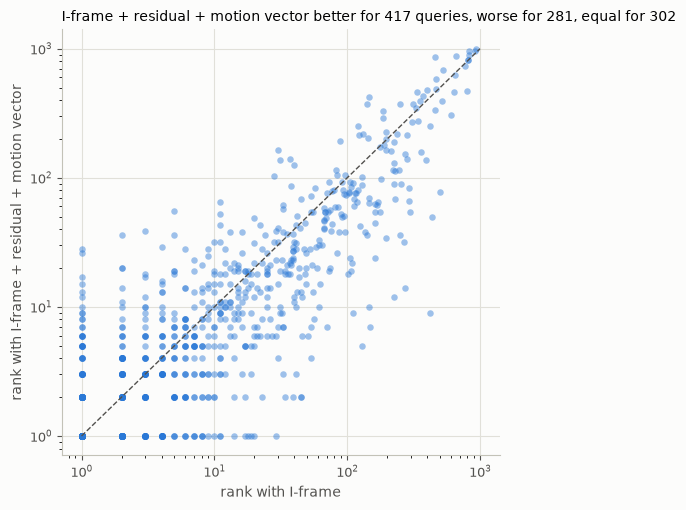

In [12]:
if emb is not None and "iframe" in emb["branches"] and len(emb["branches"]) > 1:
    display(an.complementarity_table(emb, base=("iframe",), k=10))
    display(an.complementarity_table(emb, base=("iframe",), k=1))
    an.plot_rank_scatter(emb, ["iframe"], emb["branches"])
    plt.show()
elif emb is not None:
    display(Markdown("_Needs a model with the I-frame branch and at least one other._"))

## 5. Training-time ablation: runs trained with different branches

Section 4 removes branches from one trained model. Here each run was **trained** with its own set of branches (`--visual_branches`) under the same data, schedule and budget, so it shows what each combination can reach on its own. Add the runs to `RUNS` as they finish; with a single run this section repeats section 3.

In [13]:
if len(results) > 1:
    reference = results.iloc[0]
    delta = results[["t2v_R@1", "t2v_R@5", "t2v_R@10", "t2v_MedR", "v2t_R@1", "v2t_R@10"]].copy()
    for column in ("t2v_R@1", "t2v_R@10", "v2t_R@1"):
        delta[f"Δ {column} vs {results.index[0]}"] = results[column] - reference[column]
    delta.insert(0, "branches", results["branches"])
    display(delta)
else:
    display(Markdown("_Only one run with embeddings so far._"))

_Only one run with embeddings so far._

## 6. Similarity structure

Cosine similarity between the first 30 captions (rows) and their videos (columns). The correct pairs are the diagonal: a working model shows a dark diagonal on a lighter background. The second figure uses the I-frame branch alone, the third the non-I-frame branches, when the model has them.

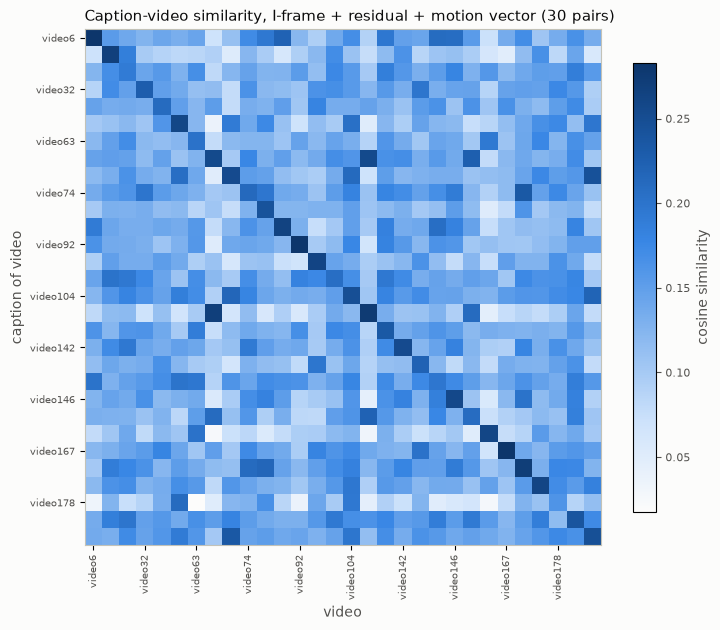

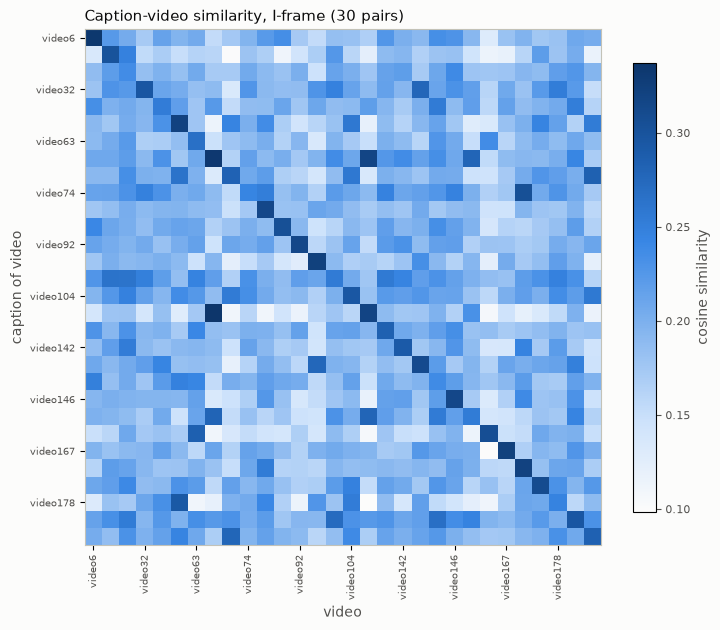

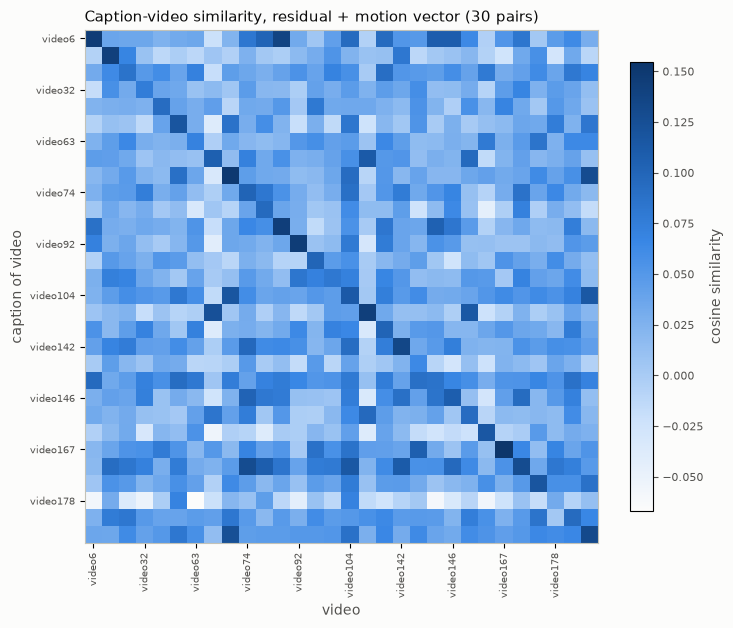

In [14]:
if emb is not None:
    an.plot_similarity_heatmap(emb, n=30)
    plt.show()
    if len(emb["branches"]) > 1 and "iframe" in emb["branches"]:
        an.plot_similarity_heatmap(emb, n=30, branches=["iframe"])
        plt.show()
        an.plot_similarity_heatmap(emb, n=30, branches=[b for b in emb["branches"] if b != "iframe"])
        plt.show()

## 7. Qualitative examples

Randomly drawn (fixed seed) successes (correct item ranked first) and failures (correct item below rank 10) of the reference model. For each query the table lists the top retrieved items; `correct` marks the ground truth.

### Text → video: success

,query caption,ground truth,ground-truth rank,position,retrieved video,retrieved video's caption,similarity,correct
0,a few girls dance and sing on a stage,video4142,1,1,video4142,a few girls dance and sing on a stage,0.26,True
1,a few girls dance and sing on a stage,video4142,1,2,video2622,a group of people dance in a gym,0.25,False
2,a few girls dance and sing on a stage,video4142,1,3,video3483,a band and dances perform on stage,0.24,False
3,a few girls dance and sing on a stage,video4142,1,4,video57,a couple of girls and boys singing and dancing on a stage,0.24,False
4,a few girls dance and sing on a stage,video4142,1,5,video3878,a blonde judge cheers a girl that is singing,0.24,False
5,a fifa press conference is going on,video5403,1,1,video5403,a fifa press conference is going on,0.28,True
6,a fifa press conference is going on,video5403,1,2,video6751,usa president barack obama talking standing on the dias,0.23,False
7,a fifa press conference is going on,video5403,1,3,video1988,the news reading woman in violet dress do the interview with two persons,0.22,False
8,a fifa press conference is going on,video5403,1,4,video1998,a man is reporting news on vladimir putin,0.22,False
9,a fifa press conference is going on,video5403,1,5,video3160,a clip from a football match,0.21,False


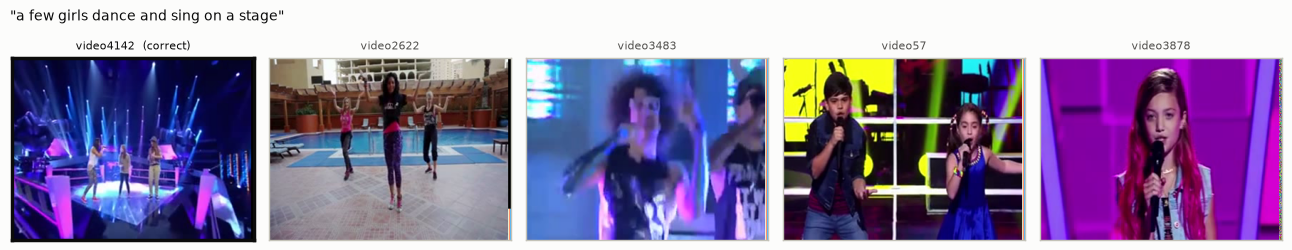

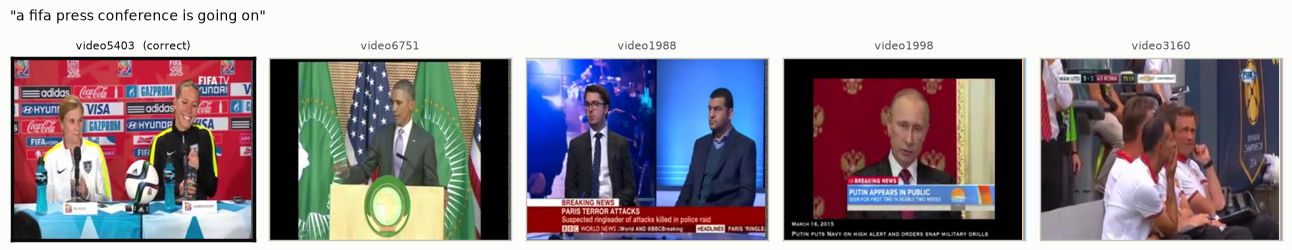

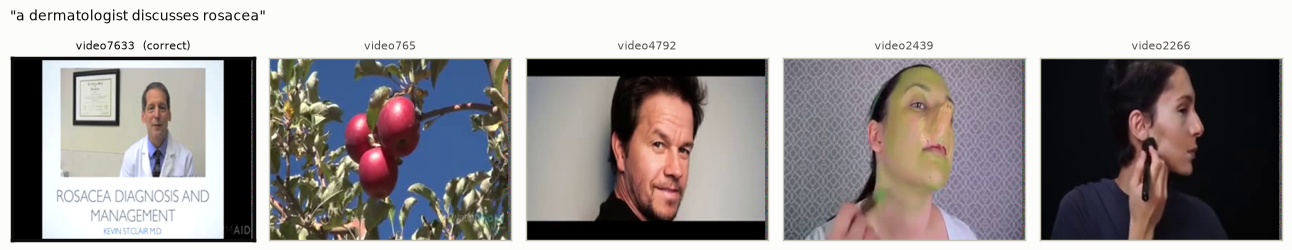

### Text → video: failure

,query caption,ground truth,ground-truth rank,position,retrieved video,retrieved video's caption,similarity,correct
0,some one showing the video of different colours of helmet,video102,18,1,video6282,a video showing the various games of xbox live,0.23,False
1,some one showing the video of different colours of helmet,video102,18,2,video4020,a boy stands near a brown and white horse while a narrator talks about the horse attac...,0.22,False
2,some one showing the video of different colours of helmet,video102,18,3,video6397,a cartoon of the ocean,0.22,False
3,some one showing the video of different colours of helmet,video102,18,4,video2855,a short intro to how images on tvs are displayed,0.22,False
4,some one showing the video of different colours of helmet,video102,18,5,video7742,a man creating icons on a computer,0.22,False
5,a group is smiling,video364,38,1,video4792,a woman sits on a couch holding a glass of white wine,0.23,False
6,a group is smiling,video364,38,2,video8548,a band is performing a song to a crowd,0.23,False
7,a group is smiling,video364,38,3,video9154,a man is holding a snake,0.23,False
8,a group is smiling,video364,38,4,video6700,a child is smiling,0.22,False
9,a group is smiling,video364,38,5,video3570,a group of high schoolers eat some food outsie,0.22,False


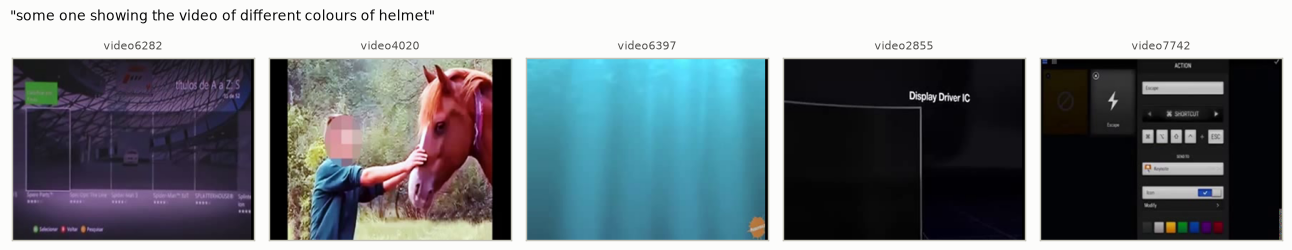

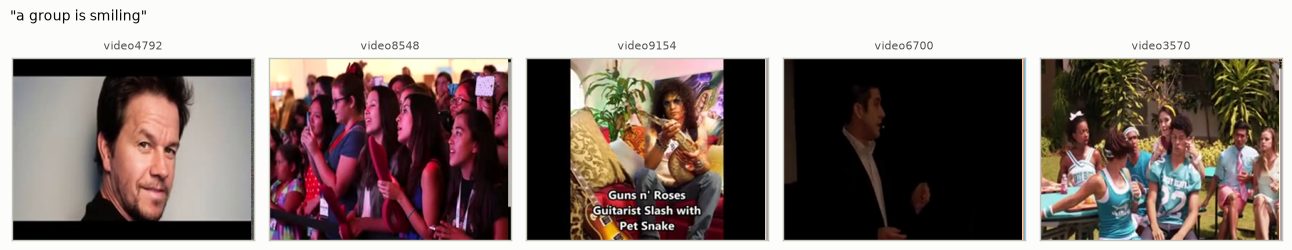

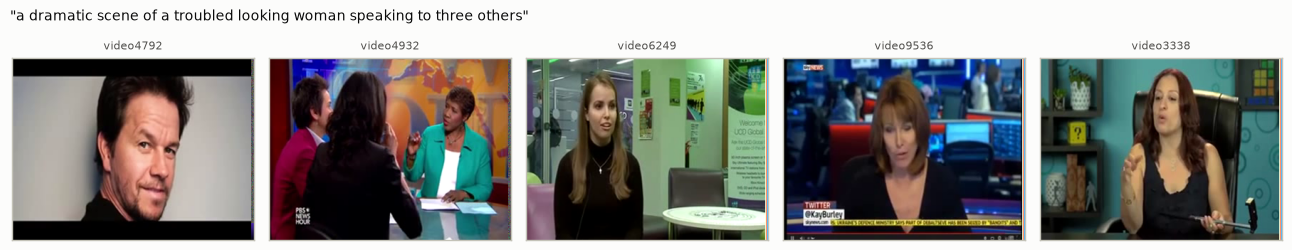

In [15]:
if emb is not None:
    picks = an.pick_examples(emb, direction="t2v", n=N_EXAMPLES, seed=SEED)
    for kind, indices in picks.items():
        display(Markdown(f"### Text → video: {kind}"))
        if not indices:
            display(Markdown("_none_"))
            continue
        display(an.qualitative_text_to_video(emb, indices, top_k=TOP_K))
        for q in indices:                              # thumbnails, when coviar and the videos are available
            if an.show_retrieved_videos(emb, q, FEATURES_PATH, top_k=TOP_K) is not None:
                plt.show()

In [16]:
if emb is not None:
    picks = an.pick_examples(emb, direction="v2t", n=N_EXAMPLES, seed=SEED)
    for kind, indices in picks.items():
        display(Markdown(f"### Video → text: {kind}"))
        display(an.qualitative_video_to_text(emb, indices, top_k=TOP_K) if indices else Markdown("_none_"))

### Video → text: success

,query video,ground-truth caption,ground-truth rank,position,retrieved caption,similarity,correct
0,video4127,a roll of film counting down from ten to one,1,1,a roll of film counting down from ten to one,0.25,True
1,video4127,a roll of film counting down from ten to one,1,2,a black and white movie clip,0.23,False
2,video4127,a roll of film counting down from ten to one,1,3,a movie trailer shows some movie scenes,0.22,False
3,video4127,a roll of film counting down from ten to one,1,4,a beautiful scene on the screen,0.22,False
4,video4127,a roll of film counting down from ten to one,1,5,a clip from a movie is playing,0.22,False
5,video5245,a man is holding a rifle and inserting a bullet into it,1,1,a man is holding a rifle and inserting a bullet into it,0.23,True
6,video5245,a man is holding a rifle and inserting a bullet into it,1,2,a clip of a meteorite and where they hit on the moon,0.22,False
7,video5245,a man is holding a rifle and inserting a bullet into it,1,3,a bionic eye successfully implanted in a robot,0.21,False
8,video5245,a man is holding a rifle and inserting a bullet into it,1,4,small switches are being placed onto a machine while a man describes the activity,0.21,False
9,video5245,a man is holding a rifle and inserting a bullet into it,1,5,a roll of film counting down from ten to one,0.20,False


### Video → text: failure

,query video,ground-truth caption,ground-truth rank,position,retrieved caption,similarity,correct
0,video147,a man cooking chicken,39,1,there is a woman is making a dish with milk,0.26,False
1,video147,a man cooking chicken,39,2,a cook adding ingredients to a bowl,0.25,False
2,video147,a man cooking chicken,39,3,a cooking demonstration on how to make fried cheese puffs,0.25,False
3,video147,a man cooking chicken,39,4,2 women making a cake,0.24,False
4,video147,a man cooking chicken,39,5,a man is making a liquid item and put it into the mixer grinder,0.24,False
5,video400,a boy band is signing about keeping his heart strong,74,1,a band and dances perform on stage,0.24,False
6,video400,a boy band is signing about keeping his heart strong,74,2,a band is performing on stage,0.24,False
7,video400,a boy band is signing about keeping his heart strong,74,3,a couple of girls and boys singing and dancing on a stage,0.24,False
8,video400,a boy band is signing about keeping his heart strong,74,4,a band is performing a song on stage,0.23,False
9,video400,a boy band is signing about keeping his heart strong,74,5,a band is performing a song on stage,0.23,False


## 8. Excluded videos

Videos that could not be decoded are removed from the candidate pool together with their captions, and are listed here.

In [17]:
failed = pd.DataFrame([{"run": run["name"], "split": split, "video_id": v}
                       for run in runs for split, e in run["embeddings"].items() for v in e["failed_video_ids"]])
display(failed if len(failed) else Markdown("_No video was excluded._"))

_No video was excluded._

## 9. Conclusions

_Write the conclusions here once the runs are in: which branches the model relies on (section 4), what each combination reaches when trained on its own (section 5), and whether the non-I-frame branches recover queries the I-frame misses (section 4, last part)._